# Démonstration des modèles

In [2]:
# Permet d'ouvrir les animations dans des fenêtres interactives séparées 
%matplotlib widget
%load_ext autoreload
%autoreload 2

## Mouvement aléatoire

/home/yra/Documents/Mod_Geom/poiscaille/alt_random_movement.py:48: UserWarning: frames=count(0) which we can infer the length of, did not pass an explicit *save_count* and passed cache_frame_data=True.  To avoid a possibly unbounded cache, frame data caching has been disabled. To suppress this warning either pass `cache_frame_data=False` or `save_count=MAX_FRAMES`.
  ani = animation.FuncAnimation(fig, animate, frames=itertools.count(),


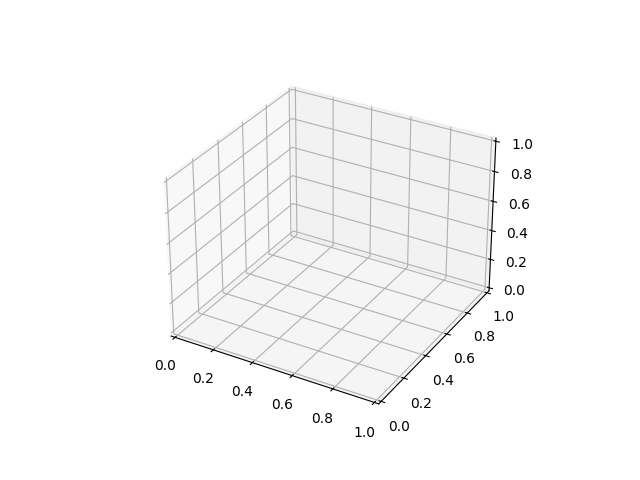

In [2]:
import alt_random_movement

## Effet Trafalgar

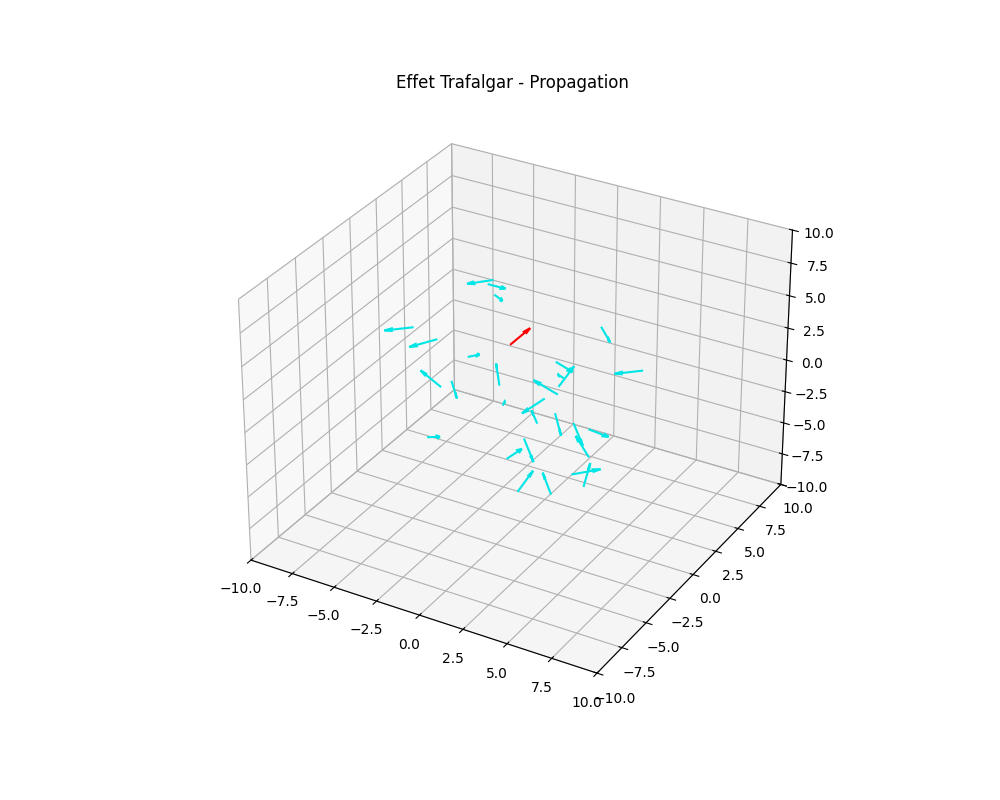

In [3]:
from trafalgar_effect import TrafalgarAnimationManager

manager_2 = TrafalgarAnimationManager()
manager_2.create_animation()

# Règles comportementales d'Aoki avec limitation de l'influence

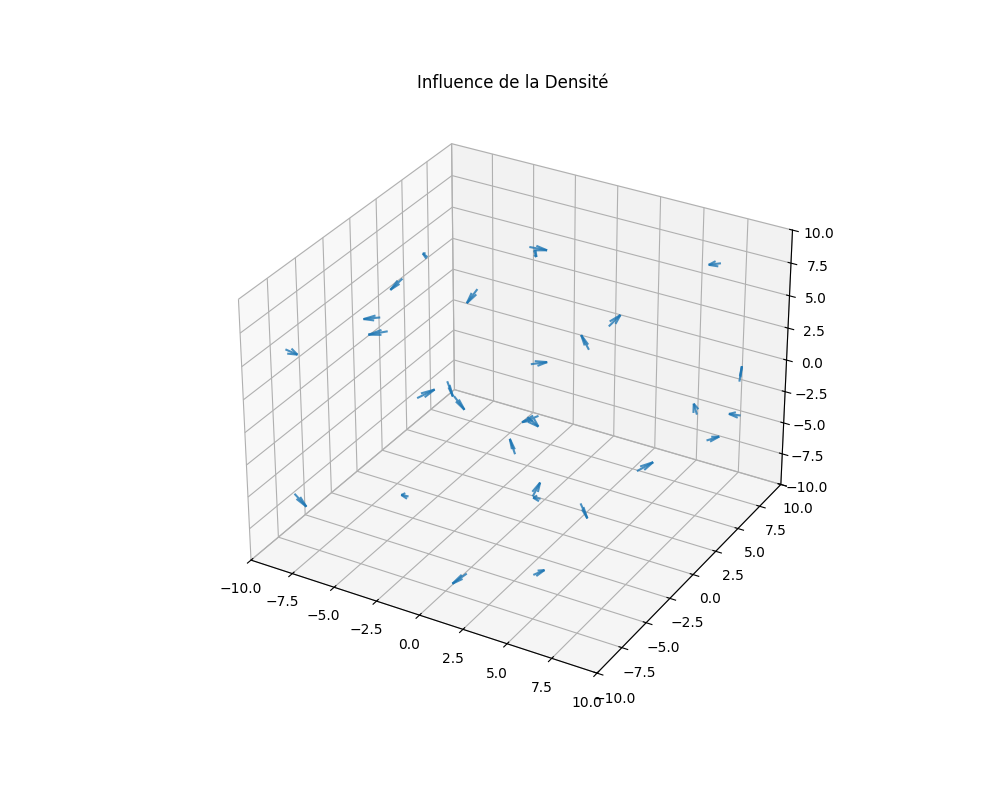

In [4]:
from density_influence import DensityAnimationManager

manager_4 = DensityAnimationManager()
manager_4.create_animation()

# Réseau d'influence avec cône de vision

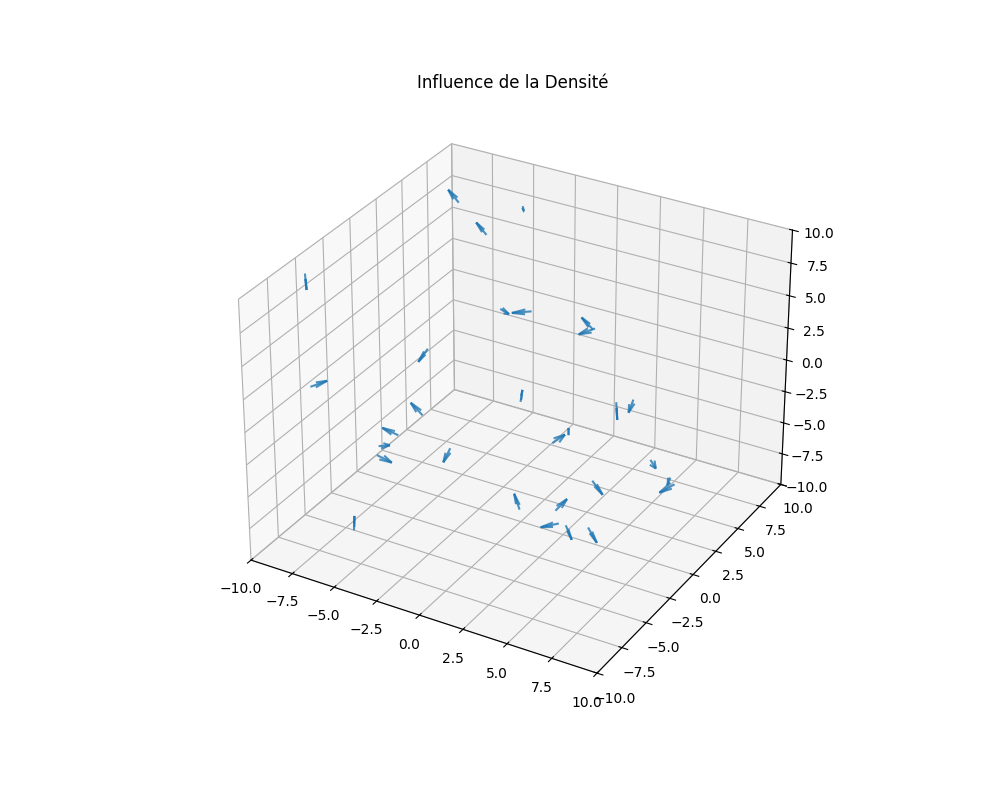

In [5]:
from influence_network import NetworkAnimationManager

manager_5 = NetworkAnimationManager()
manager_5.create_animation()

## Modèle final - conglomérat des modèles précédents

Des sliders sont accessibles pour changer en live les variables essentielles à la simulation.

Utiliser les touches directionnelles pour changer le courant (en X et Y)

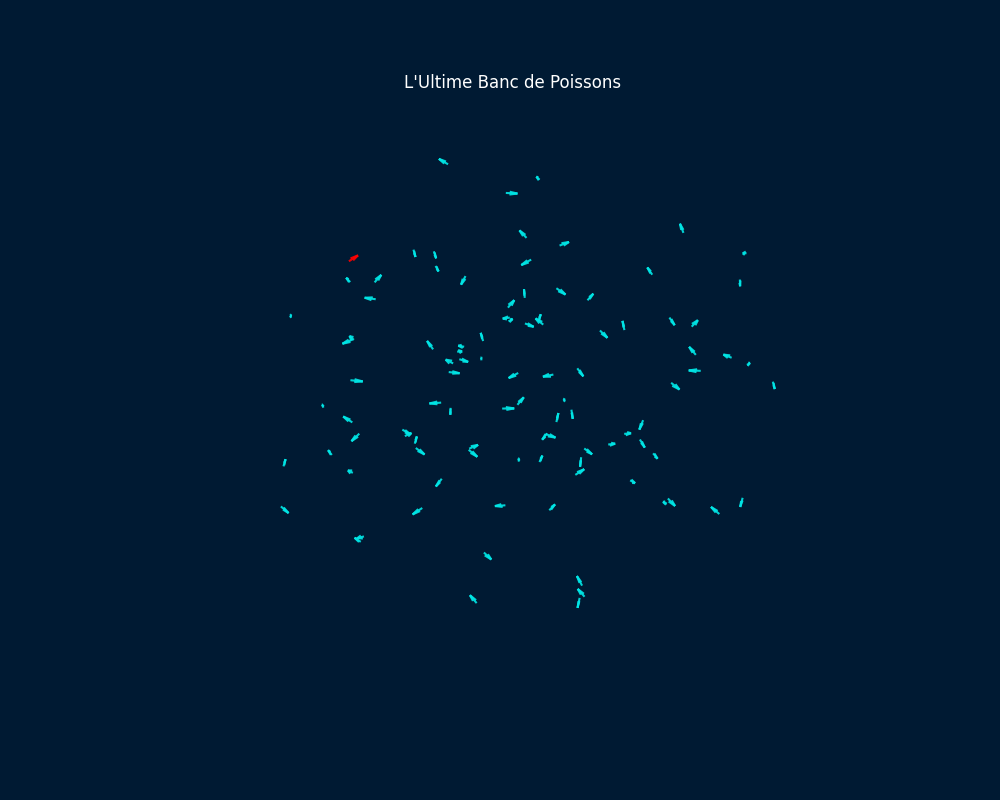

In [3]:
from final_model import UltimateAnimationManager
import ipywidgets as widgets
from IPython.display import display


manager_final = UltimateAnimationManager()

#Sliders pour les variables

## Distances
slider_dist_rep = widgets.FloatSlider(value=manager_final.dist_repulsion,
                                      min=0.0, max=5.0, step=0.1, description='Dist Répuls:')
slider_dist_ali = widgets.FloatSlider(value=manager_final.dist_alignement,
                                      min=0.0, max=10.0, step=0.1, description='Dist Align:')
slider_dist_att = widgets.FloatSlider(value=manager_final.dist_attraction,
                                      min=0.0, max=15.0, step=0.1, description='Dist Attrac:')

## Coefficients
slider_k_rep = widgets.FloatSlider(value=manager_final.k_repulsion,
                                   min=0.0, max=10.0, step=0.1, description='K Répulsion:')
slider_k_att = widgets.FloatSlider(value=manager_final.k_attraction,
                                   min=-5.0, max=0.0, step=0.1, description='K Attraction:')

## Vitesses
slider_norm_spd = widgets.FloatSlider(value=manager_final.normal_speed, min=1.0, max=10.0, step=0.5, description='Vit Normale:')
slider_cont_spd = widgets.FloatSlider(value=manager_final.contaminated_speed, min=1.0, max=15.0, step=0.5, description='Vit Contam:')

## Callbacks
def update_dist_rep(change): 
    manager_final.dist_repulsion = change.new
def update_dist_ali(change): 
    manager_final.dist_alignement = change.new
def update_dist_att(change): 
    manager_final.dist_attraction = change.new
def update_k_rep(change): 
    manager_final.k_repulsion = change.new
def update_k_att(change): 
    manager_final.k_attraction = change.new
def update_norm_spd(change): 
    manager_final.normal_speed = change.new
def update_cont_spd(change): 
    manager_final.contaminated_speed = change.new

# Liaison callbacks
slider_dist_rep.observe(update_dist_rep, names='value')
slider_dist_ali.observe(update_dist_ali, names='value')
slider_dist_att.observe(update_dist_att, names='value')
slider_k_rep.observe(update_k_rep, names='value')
slider_k_att.observe(update_k_att, names='value')
slider_norm_spd.observe(update_norm_spd, names='value')
slider_cont_spd.observe(update_cont_spd, names='value')

# -UI en colonnes
ui = widgets.HBox([
    widgets.VBox([slider_dist_rep, slider_dist_ali, slider_dist_att]),
    widgets.VBox([slider_k_rep, slider_k_att]),
    widgets.VBox([slider_norm_spd, slider_cont_spd])
])

display(ui)

# Lancer l'anim
manager_final.create_animation()